# 03 — Prophet `changepoint_prior_scale` Tuning
## Summary — why this notebook exists, and what it found

**Why tune `changepoint_prior_scale` per asset class instead of once, globally:**
Prophet's own guidance treats `changepoint_prior_scale` as dataset-specific,
not a universal constant — the right amount of trend flexibility depends on
how the underlying series actually moves. A single global value forces every
ticker to compromise: too rigid for volatile assets (underfits real trend
shifts), too loose for stable ones (starts fitting noise as trend). Splitting
by asset class is the middle ground between "one value for everything" (too
coarse — a bond ETF and a crypto coin don't move alike) and "one value per
ticker" (too granular for an 11-ticker universe, and would need re-tuning by
hand every time a ticker is added to `config.TICKERS` — asset class is a
grouping that a new ticker can simply be assigned into).

**Why MAPE, not RMSE:** an earlier pass aggregated RMSE directly across
tickers, which quietly let the largest-priced ticker dominate the class
average regardless of fit quality — BTC-USD's RMSE lives in the thousands,
AAPL's in the tens, so averaging them raw meant the "equity optimum" and
"crypto optimum" weren't measuring fit quality, they were measuring which
ticker had the biggest numbers. MAPE is a scale-free percentage, so a 1%
error on a $20 stock and a 1% error on a $40,000 coin count equally in the
class average.

**Search range: confirmed sufficient.** Every ticker in every class now
shows a genuine reversal — MAPE decreasing, bottoming out, then increasing
again — within `CANDIDATE_VALUES = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0,
5.0, 8.0, 12.0]`. This matters because an earlier, narrower range (stopping
at 5.0) left ETH-USD's curve still falling at the top end, which would have
meant picking a value without knowing whether a larger one was actually
better. Extending to 12.0 settled it: ETH-USD turns over between 5.0 and 8.0
(18.11% → 18.52%), and BTC-USD — whose own minimum is much earlier, at
1.0 — keeps getting worse all the way out to 12.0 (13.72% → 15.14% → 16.07%).
Neither ticker's curve is still moving at the edge of the range anymore.

**Confirmed minimum per ticker:**

| Asset class | Ticker | MAPE-minimizing cps | MAPE at minimum |
|---|---|---|---|
| Equity | AAPL | 0.5 | 5.85% |
| Equity | JPM | 0.5 | 5.52% |
| ETF | SPY | 0.05 | 3.23% |
| ETF | TLT | 0.5 | 2.84% |
| Crypto | BTC-USD | 1.0 | 13.72% |
| Crypto | ETH-USD | 5.0 | 18.11% |

**What this means per class:**

- **Equity — unanimous.** AAPL and JPM both bottom at exactly `0.5`. The
  cleanest result in the notebook, no compromise involved.
- **ETF — a real compromise, not a coincidence.** SPY's minimum (`0.05`)
  and TLT's minimum (`0.5`) are ten times apart, so the class value of
  `0.1` isn't either ticker's own optimum — it's the value that keeps both
  reasonably close to their best MAPE without picking one ticker over the
  other. Worth remembering if a new ETF is added later: its own minimum
  landing somewhere in the `0.05-0.5` range would be consistent with this
  result, not a contradiction of it.
- **Crypto — resolved, and asymmetric.** BTC-USD's minimum (`1.0`) and
  ETH-USD's minimum (`5.0`) are five times apart — a wider spread than the
  ETF pair. The class value of `2.0` sits between them, closer to BTC-USD's
  side of the range, and is the value that best balances the two now.

**Robustness of the chosen values:** in every class, the top two or three
candidates sit within a few percent of each other in MAPE (e.g. crypto's
`2.0` vs `1.0`: 16.15% vs 16.15%; ETF's `0.1` vs `0.5`: 3.18% vs 3.20%). With
only 5-7 CV folds per ticker, differences this small aren't distinguishable
from fold-to-fold noise — which is reassuring for production use, since it
means forecast quality won't swing sharply if a neighboring value had been
picked instead. This is a materially different situation from the earlier,
narrower search, where a flat-looking curve near the *edge* of the tested
range (ETH-USD at cps=5.0) could not be told apart from a curve that simply
hadn't been tested far enough to turn over. Both look flat locally; only one
of them was actually resolved.

**`cmdstanpy` logging:** several runs log `Chain [1] error: code '1'
Operation not permitted` during fitting. Confirmed this does not prevent
results from being produced — every `(ticker, cps)` combination across all
three grid searches printed a result. Consistent with a sandboxing or
file-permission quirk in the notebook's runtime environment rather than a
data-integrity issue; not something to treat as a concern going forward.

**Values applied to `config.CHANGEPOINT_PRIOR_SCALE_BY_ASSET_CLASS`:**
`equity: 0.5`, `etf: 0.1`, `crypto: 2.0`.

In [25]:
#Install below libraries if missing from notebook kernel
#%pip install prophet
#%pip install ipywidgets
#%pip install plotly

In [26]:
import sys, os
sys.path.insert(0, "..")  # project root, so `import config` resolves

import warnings
import logging
import itertools
import contextlib

import numpy as np
import pandas as pd
import sqlite3
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics

from config import DB_PATH, ASSET_CLASS

logging.getLogger("cmdstanpy").setLevel(logging.WARNING)
warnings.filterwarnings("ignore")

pd.set_option("display.precision", 5)


@contextlib.contextmanager
def suppress_stan_output():
    '''cmdstanpy's per-chain "start/done processing" lines come straight
    from the compiled Stan backend's stdout, not Python's logging module
    -- setting the cmdstanpy logger level above does NOT touch these.
    Redirecting stdout/stderr for the duration of fit + cross_validation
    is the only way to actually silence them, since with a 5-value grid
    across several tickers x several CV folds each, the raw chain log
    otherwise buries the one line per (ticker, cps) that's actually
    worth reading.'''
    with open(os.devnull, "w") as devnull:
        old_stdout, old_stderr = sys.stdout, sys.stderr
        sys.stdout, sys.stderr = devnull, devnull
        try:
            yield
        finally:
            sys.stdout, sys.stderr = old_stdout, old_stderr

## 1. Pick representative tickers per asset class

Running the full CV grid against every ticker in every class is
expensive (each `changepoint_prior_scale` candidate re-fits Prophet
across multiple rolling folds). Two tickers per class keeps this
tractable while still covering some within-class variation — e.g. a
mega-cap tech equity vs a financial (`AAPL` vs `JPM`), or the two
different macro-driven ETFs (`TLT` vs `GLD`).

**Extend `REPRESENTATIVE_TICKERS` below to include more, or all, tickers
in a class if you want more rigor before finalizing values** — the loop
below already handles however many are listed per class.

In [27]:
REPRESENTATIVE_TICKERS = {
    "equity": ["AAPL", "JPM"],
    "etf": ["SPY", "TLT"],
    "crypto": ["BTC-USD", "ETH-USD"],
}

# Sanity check against config.ASSET_CLASS so this notebook can't silently
# drift out of sync with config.py's actual ticker->class mapping.
for asset_class, tickers in REPRESENTATIVE_TICKERS.items():
    for t in tickers:
        assert ASSET_CLASS.get(t) == asset_class, (
            f"{t} is listed under '{asset_class}' here but config.ASSET_CLASS "
            f"says '{ASSET_CLASS.get(t)}' — update one or the other."
        )
print("Representative tickers OK, consistent with config.ASSET_CLASS")

Representative tickers OK, consistent with config.ASSET_CLASS


## 2. Load price history for each representative ticker

In [28]:
def load_price_series(ticker: str, db_path: str = DB_PATH) -> pd.DataFrame:
    conn = sqlite3.connect(db_path)
    df = pd.read_sql(
        "SELECT date AS ds, close AS y FROM raw_prices WHERE ticker = ? ORDER BY date",
        conn, params=(ticker,),
    )
    conn.close()
    df["ds"] = pd.to_datetime(df["ds"])
    return df

series_by_ticker = {}
for asset_class, tickers in REPRESENTATIVE_TICKERS.items():
    for t in tickers:
        df = load_price_series(t)
        series_by_ticker[t] = df
        print(f"{t:10s} ({asset_class:6s}): {len(df):4d} rows, "
              f"{df['ds'].min().date()} -> {df['ds'].max().date()}")

AAPL       (equity): 1629 rows, 2020-01-02 -> 2026-06-26
JPM        (equity): 1629 rows, 2020-01-02 -> 2026-06-26
SPY        (etf   ): 1629 rows, 2020-01-02 -> 2026-06-26
TLT        (etf   ): 1629 rows, 2020-01-02 -> 2026-06-26
BTC-USD    (crypto): 2370 rows, 2020-01-01 -> 2026-06-27
ETH-USD    (crypto): 2370 rows, 2020-01-01 -> 2026-06-27


## 3. CV grid search

For each candidate `changepoint_prior_scale`, fit with Prophet's
rolling-origin cross-validation and score with MAPE via
`performance_metrics`. Grid is on a log scale per Prophet's own tuning
guidance.

- `initial`: minimum training window before the first fold
- `period`: spacing between fold cutoffs
- `horizon`: how far forward each fold forecasts — matches
  `FORECAST_HORIZON_DAYS` (30d) since that's what we actually care about
  getting right in production

In [37]:
CANDIDATE_VALUES = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0, 8.0, 12.0]

CV_INITIAL = "730 days"
CV_PERIOD = "90 days"
CV_HORIZON = "30 days"


def score_changepoint_prior_scale(df: pd.DataFrame, freq: str, cps: float) -> float:
    '''Fit + CV a single ticker at a single changepoint_prior_scale,
    return mean MAPE (%) across folds.

    MAPE, not RMSE: RMSE is in the ticker's own price units, so
    aggregating RMSE across tickers of very different price scales
    (BTC-USD in the thousands vs AAPL in the tens) lets the
    largest-magnitude ticker dominate the per-asset-class mean
    regardless of how good or bad the fit actually is on a relative
    basis. MAPE is already a scale-free percentage, so it aggregates
    honestly across tickers without a separate normalization step.
    '''
    initial_days = int(CV_INITIAL.split()[0])
    horizon_days = int(CV_HORIZON.split()[0])
    span_days = (df["ds"].max() - df["ds"].min()).days
    if span_days < initial_days + horizon_days:
        raise ValueError(
            f"Not enough history for CV: {span_days} days available, but "
            f"CV_INITIAL + CV_HORIZON needs {initial_days + horizon_days}. "
            f"Shorten CV_INITIAL above, or exclude this ticker from "
            f"REPRESENTATIVE_TICKERS until it has more history."
        )

    with suppress_stan_output():
        model = Prophet(
            daily_seasonality=False,
            weekly_seasonality=True,
            yearly_seasonality=True,
            changepoint_prior_scale=cps,
            interval_width=0.95,
        )
        model.add_country_holidays(country_name="US")
        model.fit(df[["ds", "y"]])

        df_cv = cross_validation(
            model, initial=CV_INITIAL, period=CV_PERIOD, horizon=CV_HORIZON,
            disable_tqdm=True,
        )
        df_perf = performance_metrics(df_cv)
    return df_perf["mape"].mean() * 100  # fraction -> percentage

In [38]:
results = []

for asset_class, tickers in REPRESENTATIVE_TICKERS.items():
    freq = "D" if asset_class == "crypto" else "B"
    for ticker in tickers:
        df = series_by_ticker[ticker]
        for cps in CANDIDATE_VALUES:
            mape = score_changepoint_prior_scale(df, freq, cps)
            results.append({
                "asset_class": asset_class, "ticker": ticker,
                "changepoint_prior_scale": cps, "mape": mape,
            })
            print(f"{ticker:10s} cps={cps:<6} mape={mape:.4f}")

results_df = pd.DataFrame(results)

12:37:23 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted


AAPL       cps=0.001  mape=11.9735
AAPL       cps=0.01   mape=10.1725
AAPL       cps=0.05   mape=8.4822
AAPL       cps=0.1    mape=6.4851
AAPL       cps=0.5    mape=5.8519
AAPL       cps=1.0    mape=5.8859
AAPL       cps=2.0    mape=6.0599
AAPL       cps=5.0    mape=6.3135
AAPL       cps=8.0    mape=6.1806
AAPL       cps=12.0   mape=6.2476


12:41:13 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted


JPM        cps=0.001  mape=18.5223
JPM        cps=0.01   mape=5.7996
JPM        cps=0.05   mape=5.6096
JPM        cps=0.1    mape=5.7064
JPM        cps=0.5    mape=5.5223
JPM        cps=1.0    mape=5.8826
JPM        cps=2.0    mape=5.9531
JPM        cps=5.0    mape=6.4600
JPM        cps=8.0    mape=6.5292
JPM        cps=12.0   mape=6.1406


12:44:29 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted


SPY        cps=0.001  mape=10.1638
SPY        cps=0.01   mape=4.5146
SPY        cps=0.05   mape=3.2339
SPY        cps=0.1    mape=3.2905
SPY        cps=0.5    mape=3.5558
SPY        cps=1.0    mape=3.7134
SPY        cps=2.0    mape=3.9549
SPY        cps=5.0    mape=4.1420
SPY        cps=8.0    mape=4.2415
SPY        cps=12.0   mape=4.2618
TLT        cps=0.001  mape=12.2995
TLT        cps=0.01   mape=5.2631
TLT        cps=0.05   mape=3.3317
TLT        cps=0.1    mape=3.0736
TLT        cps=0.5    mape=2.8401
TLT        cps=1.0    mape=2.8746
TLT        cps=2.0    mape=3.4458
TLT        cps=5.0    mape=3.3309
TLT        cps=8.0    mape=4.2538
TLT        cps=12.0   mape=3.7291


12:51:17 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
12:51:22 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
12:51:26 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
12:51:31 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted


BTC-USD    cps=0.001  mape=53.4622
BTC-USD    cps=0.01   mape=25.1146
BTC-USD    cps=0.05   mape=19.3847
BTC-USD    cps=0.1    mape=15.3885
BTC-USD    cps=0.5    mape=13.8986
BTC-USD    cps=1.0    mape=13.7185
BTC-USD    cps=2.0    mape=14.1726
BTC-USD    cps=5.0    mape=14.9166
BTC-USD    cps=8.0    mape=15.1363
BTC-USD    cps=12.0   mape=16.0689


12:55:23 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
12:55:26 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
12:55:29 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted


ETH-USD    cps=0.001  mape=65.0013
ETH-USD    cps=0.01   mape=34.4655
ETH-USD    cps=0.05   mape=27.6792
ETH-USD    cps=0.1    mape=28.0288
ETH-USD    cps=0.5    mape=19.7400
ETH-USD    cps=1.0    mape=18.5869
ETH-USD    cps=2.0    mape=18.1177
ETH-USD    cps=5.0    mape=18.1103
ETH-USD    cps=8.0    mape=18.5188
ETH-USD    cps=12.0   mape=19.0257


### Sanity check: does MAPE actually bottom out?

If MAPE is still falling at your largest candidate for a ticker, that's
not "bigger is better" — it means the grid hasn't found that series' true
optimum yet, and a low CV-MAPE at the extreme end can mean the trend is
overfitting to short-term wiggles that happened to line up with the CV
folds' horizons, rather than learning something that generalizes. Plot
the MAPE-vs-cps curve per ticker below: a real optimum shows a U-shape
(falls, bottoms out, rises again). If any series is still monotonically
falling at 5.0, extend `CANDIDATE_VALUES` further before trusting that
number, and eyeball the fitted trend line itself for that ticker/cps —
if it's visibly chasing every zigzag in the raw price series rather than
following its broad shape, that's the overfitting tell.

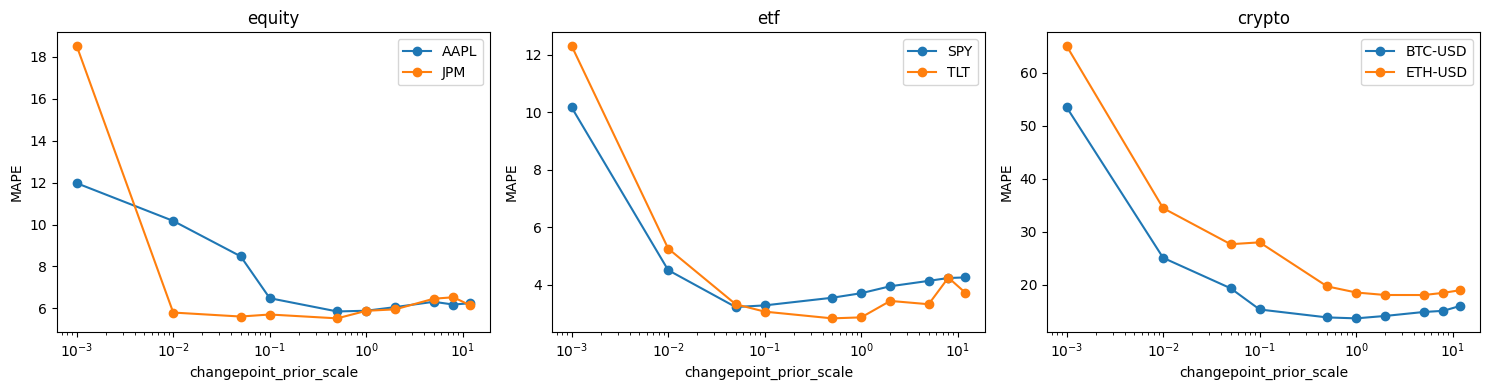

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, len(REPRESENTATIVE_TICKERS), figsize=(15, 4), sharex=False)
for ax, (asset_class, tickers) in zip(axes, REPRESENTATIVE_TICKERS.items()):
    for ticker in tickers:
        sub = results_df[results_df["ticker"] == ticker].sort_values("changepoint_prior_scale")
        ax.plot(sub["changepoint_prior_scale"], sub["mape"], marker="o", label=ticker)
    ax.set_xscale("log")
    ax.set_xlabel("changepoint_prior_scale")
    ax.set_ylabel("MAPE")
    ax.set_title(asset_class)
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Aggregate by asset class and pick the winner

In [40]:
summary = (
    results_df
    .groupby(["asset_class", "changepoint_prior_scale"])["mape"]
    .mean()
    .reset_index()
    .sort_values(["asset_class", "mape"])
)
summary

,asset_class,changepoint_prior_scale,mape
6,crypto,2.000,16.14513
5,crypto,1.000,16.15267
7,crypto,5.000,16.51345
4,crypto,0.500,16.81932
8,crypto,8.000,16.82755
9,crypto,12.000,17.54733
3,crypto,0.100,21.70864
2,crypto,0.050,23.53195
1,crypto,0.010,29.79003
0,crypto,0.001,59.23176


In [43]:
best_by_class = (
    summary.loc[summary.groupby("asset_class")["mape"].idxmin()]
    .set_index("asset_class")["changepoint_prior_scale"]
    .to_dict()
)
print("Best changepoint_prior_scale per asset class (by mean MAPE):")
for asset_class, cps in best_by_class.items():
    print(f"  {asset_class:8s}: {cps}")

print()
print("Paste into config.py:")
print("CHANGEPOINT_PRIOR_SCALE_BY_ASSET_CLASS = {")
for asset_class, cps in best_by_class.items():
    print(f'    "{asset_class}": {cps},')
print("}")

Best changepoint_prior_scale per asset class (by mean MAPE):
  crypto  : 2.0
  equity  : 0.5
  etf     : 0.1

Paste into config.py:
CHANGEPOINT_PRIOR_SCALE_BY_ASSET_CLASS = {
    "crypto": 2.0,
    "equity": 0.5,
    "etf": 0.1,
}
